# 04 — Fixed-split likelihood-ratio calibration

**Paper:** *Presence-absence estimation in audio recordings of tropical frog communities*

## 1. Objective

This notebook replaces the previous calibration strategy with one fixed, leakage-free detector:

**labelled calls → fixed TRAIN/CALIBRATION split → frozen GMMs → LLR → one-vs-all ROC →
per-species thresholds → frozen detector**

The critical rule is:

> **The GMMs used to calculate the ROC thresholds are exactly the GMMs that will later be deployed.
> They are never re-trained after threshold calibration.**

### What comes from the paper

`[PAPER]`

- one GMM per frog species;
- diagonal covariance;
- likelihood-based species hypothesis;
- alternative model represented by the median of non-hypothesized model scores;
- one-vs-all ROC curves;
- initial operating points around `FPR = 5%`;
- final thresholds subsequently fine-tuned with manually annotated field material;
- the paper ultimately reports `M = 64` production GMMs.

### What is a replication decision

`[REPLICATION DECISION]`

The complete field-labelled material required to reproduce the authors' final threshold fine-tuning is
not available. Therefore we reserve **20% of the labelled calls per usable species for calibration**
and train the deployable GMMs on the remaining 80%.

The split is made at **complete-call level**, never at frame level.

This differs from the paper's final "train on all development material" step, but it prevents the
score-shift problem observed when thresholds calibrated with one family of GMMs are applied to a
different family of re-trained GMMs.

`f09` remains excluded because the recovered labelled corpus is insufficient for that class.

In [1]:
from pathlib import Path
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.cluster import kmeans_plusplus
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import auc, roc_curve
from sklearn.mixture import GaussianMixture

pd.set_option("display.width", 170)
pd.set_option("display.max_rows", 150)
pd.set_option("display.max_columns", 60)

CWD = Path.cwd().resolve()
REPO_ROOT = CWD.parent if CWD.name == "notebooks" else CWD

PROCESSED_DIR = REPO_ROOT / "data" / "processed"
GMM03_DIR = PROCESSED_DIR / "gmm_parameter_investigation"

FEATURES_PATH = PROCESSED_DIR / "features.npy"
LABELS_PATH = PROCESSED_DIR / "labels.npy"
CALLS_PATH = PROCESSED_DIR / "calls.csv"

# Separate output directories prevent accidental reuse of the incompatible
# artifacts produced by the previous version of notebook 04.
CALIBRATION_DIR = PROCESSED_DIR / "likelihood_ratio_calibration_fixed"
MODEL_DIR = REPO_ROOT / "models" / "gmm_fixed_calibration"

CALIBRATION_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

for path in (FEATURES_PATH, LABELS_PATH, CALLS_PATH):
    if not path.exists():
        raise FileNotFoundError(
            f"Missing {path}. Run notebooks/02_preprocessing.ipynb first."
        )

print("Repository root :", REPO_ROOT)
print("Calibration out :", CALIBRATION_DIR)
print("Frozen models   :", MODEL_DIR)

Repository root : C:\Users\sofia\Projects\PUCE\frog-presence-replication
Calibration out : C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\processed\likelihood_ratio_calibration_fixed
Frozen models   : C:\Users\sofia\Projects\PUCE\frog-presence-replication\models\gmm_fixed_calibration


## 2. Load and reconstruct complete calls

`features.npy` contains frame-level 20-dimensional m-FCC vectors. `labels.npy` contains the aligned
species code, and `calls.csv` stores the number of frames contributed by each complete labelled call.

The cumulative frame counts reconstruct the exact block of feature rows belonging to every call.

In [3]:
features = np.load(FEATURES_PATH)
labels = np.load(LABELS_PATH)
calls = pd.read_csv(CALLS_PATH).copy().reset_index(drop=True)

required = {"code", "species", "seconds", "frames"}
missing = required - set(calls.columns)
if missing:
    raise ValueError(f"calls.csv is missing required columns: {sorted(missing)}")

assert features.ndim == 2
assert features.shape[1] == 20
assert len(features) == len(labels)
assert int(calls["frames"].sum()) == len(features)

calls["call_id"] = [f"call_{i:04d}" for i in range(len(calls))]
calls["frame_stop"] = calls["frames"].cumsum().astype(int)
calls["frame_start"] = calls["frame_stop"].shift(fill_value=0).astype(int)

CALLS_BY_ID = calls.set_index("call_id", drop=False)

def get_call_features(call_id):
    row = CALLS_BY_ID.loc[call_id]
    return features[int(row.frame_start):int(row.frame_stop)]

bad = []
for row in calls.itertuples(index=False):
    block = labels[int(row.frame_start):int(row.frame_stop)]
    if len(block) != int(row.frames) or not np.all(block == row.code):
        bad.append(row.call_id)

if bad:
    raise AssertionError(f"Call reconstruction failed: {bad[:5]}")

species_inventory = (
    calls.groupby(["code", "species"], as_index=False)
    .agg(
        calls=("call_id", "size"),
        seconds=("seconds", "sum"),
        frames=("frames", "sum"),
    )
    .sort_values("code")
)
species_inventory["seconds"] = species_inventory["seconds"].round(2)

print("features:", features.shape)
print("calls   :", len(calls))
display(species_inventory)

features: (136005, 20)
calls   : 1461


,code,species,calls,seconds,frames
0,f01,Boana alfaroi,98,44.72,8650
1,f02,Dendropsophus bifurcus,99,41.72,8047
2,f03,Boana cinerascens,169,102.58,20009
3,f04,Pristimantis conspicillatus,186,77.94,15030
4,f05,Leptodactylus discodactylus,340,114.36,21852
5,f06,Osteocephalus fuscifacies,54,24.94,4826
6,f07,Boana lanciformis,101,57.84,11265
7,f08,Rhinella margaritifera,96,102.66,20244
8,f09,Dendropsophus parviceps,2,1.18,230
9,f10,Engystomops petersi,316,134.00,25852


## 3. Detector configuration

The main replication path keeps `M = 64`, the model order selected by the paper.

The recovered-corpus optimum from notebook 03 is printed, when available, only as context. It does
not alter the detector configuration in this notebook.

In [4]:
MODEL_ORDER = 64
CALIBRATION_FRACTION = 0.20
TARGET_MAX_FPR = 0.05
BASE_SEED = 20260814

EXCLUDED_CODES = {"f09"}
USABLE_CODES = tuple(
    species_inventory.loc[
        ~species_inventory["code"].isin(EXCLUDED_CODES),
        "code",
    ]
)

usable_inventory = species_inventory[
    species_inventory["code"].isin(USABLE_CODES)
].copy()

print("M                    :", MODEL_ORDER)
print("Calibration fraction :", CALIBRATION_FRACTION)
print("Maximum target FPR   :", TARGET_MAX_FPR)
print("Classes              :", USABLE_CODES)

WER03_PATH = GMM03_DIR / "wer_summary.csv"
if WER03_PATH.exists():
    wer03 = pd.read_csv(WER03_PATH)
    best03 = wer03.sort_values(
        ["WER_mean", "training_seconds_target", "n_components"]
    ).iloc[0]
    print("\nNotebook 03 recovered optimum:")
    print("  seconds    :", int(best03.training_seconds_target))
    print("  components :", int(best03.n_components))
    print("  mean WER   :", round(float(best03.WER_mean) * 100, 4), "%")

M                    : 64
Calibration fraction : 0.2
Maximum target FPR   : 0.05
Classes              : ('f01', 'f02', 'f03', 'f04', 'f05', 'f06', 'f07', 'f08', 'f10')

Notebook 03 recovered optimum:
  seconds    : 18
  components : 8
  mean WER   : 0.5012 %


## 4. Fixed 80/20 split by complete call

For each usable species:

1. shuffle complete calls using a deterministic species-specific seed;
2. reserve `ceil(20%)` for CALIBRATION;
3. use all remaining calls for TRAIN;
4. keep at least one call on each side;
5. verify zero overlap.

There is only **one split**, because there will be only **one frozen detector**.

In [5]:
def species_number(code):
    digits = "".join(ch for ch in str(code) if ch.isdigit())
    return int(digits) if digits else 0


def fixed_species_split(code):
    subset = (
        calls.loc[calls["code"] == code]
        .copy()
        .reset_index(drop=True)
    )

    n = len(subset)
    if n < 2:
        raise ValueError(f"{code} needs at least two calls.")

    n_cal = int(np.ceil(n * CALIBRATION_FRACTION))
    n_cal = max(1, min(n_cal, n - 1))

    seed = BASE_SEED + species_number(code)
    rng = np.random.default_rng(seed)
    order = rng.permutation(n)

    cal_ids = tuple(subset.iloc[order[:n_cal]]["call_id"])
    train_ids = tuple(subset.iloc[order[n_cal:]]["call_id"])

    assert set(train_ids).isdisjoint(cal_ids)

    return train_ids, cal_ids, seed


TRAIN_IDS = {}
CALIBRATION_IDS = {}
split_rows = []

for code in USABLE_CODES:
    train_ids, cal_ids, seed = fixed_species_split(code)

    TRAIN_IDS[code] = train_ids
    CALIBRATION_IDS[code] = cal_ids

    train_meta = CALLS_BY_ID.loc[list(train_ids)]
    cal_meta = CALLS_BY_ID.loc[list(cal_ids)]

    split_rows.append({
        "code": code,
        "species": train_meta["species"].iloc[0],
        "seed": seed,
        "n_total_calls": len(train_ids) + len(cal_ids),
        "n_train_calls": len(train_ids),
        "n_calibration_calls": len(cal_ids),
        "train_seconds": float(train_meta["seconds"].sum()),
        "calibration_seconds": float(cal_meta["seconds"].sum()),
        "train_frames": int(train_meta["frames"].sum()),
        "calibration_frames": int(cal_meta["frames"].sum()),
    })

split_summary = pd.DataFrame(split_rows)
display(split_summary.round(3))

,code,species,seed,n_total_calls,n_train_calls,n_calibration_calls,train_seconds,calibration_seconds,train_frames,calibration_frames
0,f01,Boana alfaroi,20260815,98,78,20,35.94,8.78,6954,1696
1,f02,Dendropsophus bifurcus,20260816,99,79,20,33.30,8.42,6423,1624
2,f03,Boana cinerascens,20260817,169,135,34,80.86,21.72,15767,4242
3,f04,Pristimantis conspicillatus,20260818,186,148,38,62.44,15.50,12044,2986
4,f05,Leptodactylus discodactylus,20260819,340,272,68,91.70,22.66,17524,4328
5,f06,Osteocephalus fuscifacies,20260820,54,43,11,19.08,5.86,3687,1139
6,f07,Boana lanciformis,20260821,101,80,21,45.62,12.22,8884,2381
7,f08,Rhinella margaritifera,20260822,96,76,20,81.38,21.28,16048,4196
8,f10,Engystomops petersi,20260824,316,252,64,106.38,27.62,20520,5332


In [6]:
all_train = set()
all_calibration = set()

for code in USABLE_CODES:
    train_set = set(TRAIN_IDS[code])
    cal_set = set(CALIBRATION_IDS[code])

    assert train_set.isdisjoint(cal_set)

    expected = set(calls.loc[calls["code"] == code, "call_id"])
    assert train_set | cal_set == expected

    # Determinism check.
    train_check, cal_check, _ = fixed_species_split(code)
    assert TRAIN_IDS[code] == train_check
    assert CALIBRATION_IDS[code] == cal_check

    all_train.update(train_set)
    all_calibration.update(cal_set)

assert all_train.isdisjoint(all_calibration)

print("Leakage          : none")
print("Split coverage   : complete")
print("Reproducibility  : OK")
print("TRAIN calls      :", len(all_train))
print("CALIBRATION calls:", len(all_calibration))

Leakage          : none
Split coverage   : complete
Reproducibility  : OK
TRAIN calls      : 1163
CALIBRATION calls: 296


## 5. GMM implementation

Each species is represented by one diagonal-covariance GMM.

Initialization follows the paper-oriented implementation already used in notebook 03:

- k-means++ initial means;
- uniform initial mixture weights;
- initial diagonal covariance based on feature variance;
- EM maximum-likelihood training.

A small covariance regularizer is retained for numerical stability.

In [7]:
def stack_call_features(call_ids):
    return np.vstack([get_call_features(cid) for cid in call_ids])


def make_initial_parameters(X, n_components, seed):
    if len(X) < n_components:
        raise ValueError(
            f"Need at least {n_components} frames, got {len(X)}."
        )

    means_init, _ = kmeans_plusplus(
        X,
        n_clusters=n_components,
        random_state=seed,
    )

    variance = np.maximum(np.var(X, axis=0, ddof=0), 1e-12)

    weights_init = np.full(
        n_components,
        1.0 / n_components,
        dtype=float,
    )

    precisions_init = np.tile(
        1.0 / variance,
        (n_components, 1),
    )

    return weights_init, means_init, precisions_init


def fit_one_gmm(X, n_components, seed):
    weights_init, means_init, precisions_init = make_initial_parameters(
        X,
        n_components,
        seed,
    )

    model = GaussianMixture(
        n_components=n_components,
        covariance_type="diag",
        weights_init=weights_init,
        means_init=means_init,
        precisions_init=precisions_init,
        n_init=1,
        random_state=seed,
        reg_covar=1e-6,
        max_iter=100,
        tol=1e-3,
        init_params="random",
    )

    with warnings.catch_warnings():
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(X)

    return model

## 6. Train the deployable GMMs on TRAIN only

These models are **final and frozen**.

They are used unchanged for threshold calibration, serialization and later field inference.
There is no second training stage after ROC calibration.

In [8]:
FROZEN_MODELS = {}
model_rows = []

for code in USABLE_CODES:
    X_train = stack_call_features(TRAIN_IDS[code])

    seed = (
        BASE_SEED
        + 1_000_000
        + MODEL_ORDER * 100
        + species_number(code)
    )

    model = fit_one_gmm(
        X_train,
        n_components=MODEL_ORDER,
        seed=seed,
    )

    FROZEN_MODELS[code] = model

    model_rows.append({
        "code": code,
        "n_train_calls": len(TRAIN_IDS[code]),
        "train_seconds": float(
            CALLS_BY_ID.loc[list(TRAIN_IDS[code]), "seconds"].sum()
        ),
        "train_frames": len(X_train),
        "n_components": model.n_components,
        "covariance_type": model.covariance_type,
        "converged": bool(model.converged_),
        "n_iter": int(model.n_iter_),
        "lower_bound": float(model.lower_bound_),
    })

model_summary = pd.DataFrame(model_rows)
display(model_summary.round(4))

if not model_summary["converged"].all():
    warnings.warn("At least one frozen GMM did not report convergence.")

,code,n_train_calls,train_seconds,train_frames,n_components,covariance_type,converged,n_iter,lower_bound
0,f01,78,35.94,6954,64,diag,True,44,-29.1073
1,f02,79,33.30,6423,64,diag,True,35,-29.7861
2,f03,135,80.86,15767,64,diag,True,43,-31.7856
3,f04,148,62.44,12044,64,diag,True,33,-27.5936
4,f05,272,91.70,17524,64,diag,True,38,-30.8694
5,f06,43,19.08,3687,64,diag,True,27,-28.8684
6,f07,80,45.62,8884,64,diag,True,28,-29.6067
7,f08,76,81.38,16048,64,diag,True,30,-28.4235
8,f10,252,106.38,20520,64,diag,True,33,-34.2476


## 7. Likelihood-ratio score

For a complete call \(X\), the normalized score under model \(k\) is

\[
s_k(X)=\frac{1}{T}\sum_{t=1}^{T}\log p(x_t|\lambda_k).
\]

For candidate class \(k\), the alternative score is the median of all non-\(k\) model scores:

\[
s_{alt,k}(X)=\operatorname{median}_{j\ne k}s_j(X).
\]

The one-vs-all likelihood-ratio score is

\[
LLR_k(X)=s_k(X)-s_{alt,k}(X).
\]

A larger positive value means candidate species \(k\) explains the call substantially better than the
alternative species models.

In [9]:
def model_scores(X_call, models=FROZEN_MODELS):
    return {
        code: float(model.score_samples(X_call).mean())
        for code, model in models.items()
    }


def one_vs_all_llr(scores):
    out = {}
    for code in scores:
        alternatives = [
            score
            for other, score in scores.items()
            if other != code
        ]
        out[code] = float(
            scores[code] - np.median(alternatives)
        )
    return out


example_true = USABLE_CODES[0]
example_call = CALIBRATION_IDS[example_true][0]

scores = model_scores(get_call_features(example_call))
llrs = one_vs_all_llr(scores)

print("Example CALIBRATION call:", example_call)
print("True species            :", example_true)

display(
    pd.DataFrame({
        "mean_log_likelihood": pd.Series(scores),
        "LLR": pd.Series(llrs),
    }).sort_values("LLR", ascending=False)
)

Example CALIBRATION call: call_0018
True species            : f01


,mean_log_likelihood,LLR
f01,-32.162314,41.173895
f03,-66.350701,6.985507
f10,-71.365953,1.970256
f04,-72.709274,0.626935
f02,-73.022129,0.157653
f05,-73.650289,-0.784588
f06,-74.454827,-1.589125
f08,-104.837372,-31.971671
f07,-113.251621,-40.385919


## 8. Score all held-out calibration calls

Each calibration call is evaluated against every candidate species.

For one candidate species:

- calls truly belonging to it are positive observations;
- calls from every other modelled species are negative observations.

No calibration call was used to fit any GMM.

In [10]:
rows = []

for true_code in USABLE_CODES:
    for call_id in CALIBRATION_IDS[true_code]:
        X_call = get_call_features(call_id)
        scores = model_scores(X_call)
        llrs = one_vs_all_llr(scores)

        for candidate_code in USABLE_CODES:
            rows.append({
                "call_id": call_id,
                "true_code": true_code,
                "candidate_code": candidate_code,
                "is_positive": int(true_code == candidate_code),
                "mean_log_likelihood": scores[candidate_code],
                "llr": llrs[candidate_code],
            })

calibration_scores = pd.DataFrame(rows)

expected = (
    sum(len(x) for x in CALIBRATION_IDS.values())
    * len(USABLE_CODES)
)
assert len(calibration_scores) == expected

print("Calibration calls :", sum(len(x) for x in CALIBRATION_IDS.values()))
print("LLR rows          :", len(calibration_scores))
display(calibration_scores.head())

Calibration calls : 296
LLR rows          : 2664


,call_id,true_code,candidate_code,is_positive,mean_log_likelihood,llr
0,call_0018,f01,f01,1,-32.162314,41.173895
1,call_0018,f01,f02,0,-73.022129,0.157653
2,call_0018,f01,f03,0,-66.350701,6.985507
3,call_0018,f01,f04,0,-72.709274,0.626935
4,call_0018,f01,f05,0,-73.650289,-0.784588


## 9. One-vs-all ROC curves

For every species independently, vary the LLR threshold and calculate TPR and FPR.

AUROC is reported as a threshold-independent separation diagnostic.

In [11]:
def make_roc(code):
    subset = calibration_scores[
        calibration_scores["candidate_code"] == code
    ]

    y_true = subset["is_positive"].to_numpy(dtype=int)
    y_score = subset["llr"].to_numpy(dtype=float)

    if len(np.unique(y_true)) != 2:
        raise ValueError(f"ROC for {code} lacks positives or negatives.")

    fpr, tpr, thresholds = roc_curve(y_true, y_score)

    return {
        "code": code,
        "fpr": fpr,
        "tpr": tpr,
        "thresholds": thresholds,
        "auroc": float(auc(fpr, tpr)),
        "n_positive": int(y_true.sum()),
        "n_negative": int((1 - y_true).sum()),
    }


ROC_DATA = {
    code: make_roc(code)
    for code in USABLE_CODES
}

roc_overview = pd.DataFrame([
    {
        "code": code,
        "auroc": d["auroc"],
        "n_positive": d["n_positive"],
        "n_negative": d["n_negative"],
    }
    for code, d in ROC_DATA.items()
])

display(roc_overview.round(4))

,code,auroc,n_positive,n_negative
0,f01,1.0000,20,276
1,f02,0.9522,20,276
2,f03,0.9994,34,262
3,f04,1.0000,38,258
4,f05,0.9774,68,228
5,f06,1.0000,11,285
6,f07,0.9988,21,275
7,f08,1.0000,20,276
8,f10,0.9963,64,232


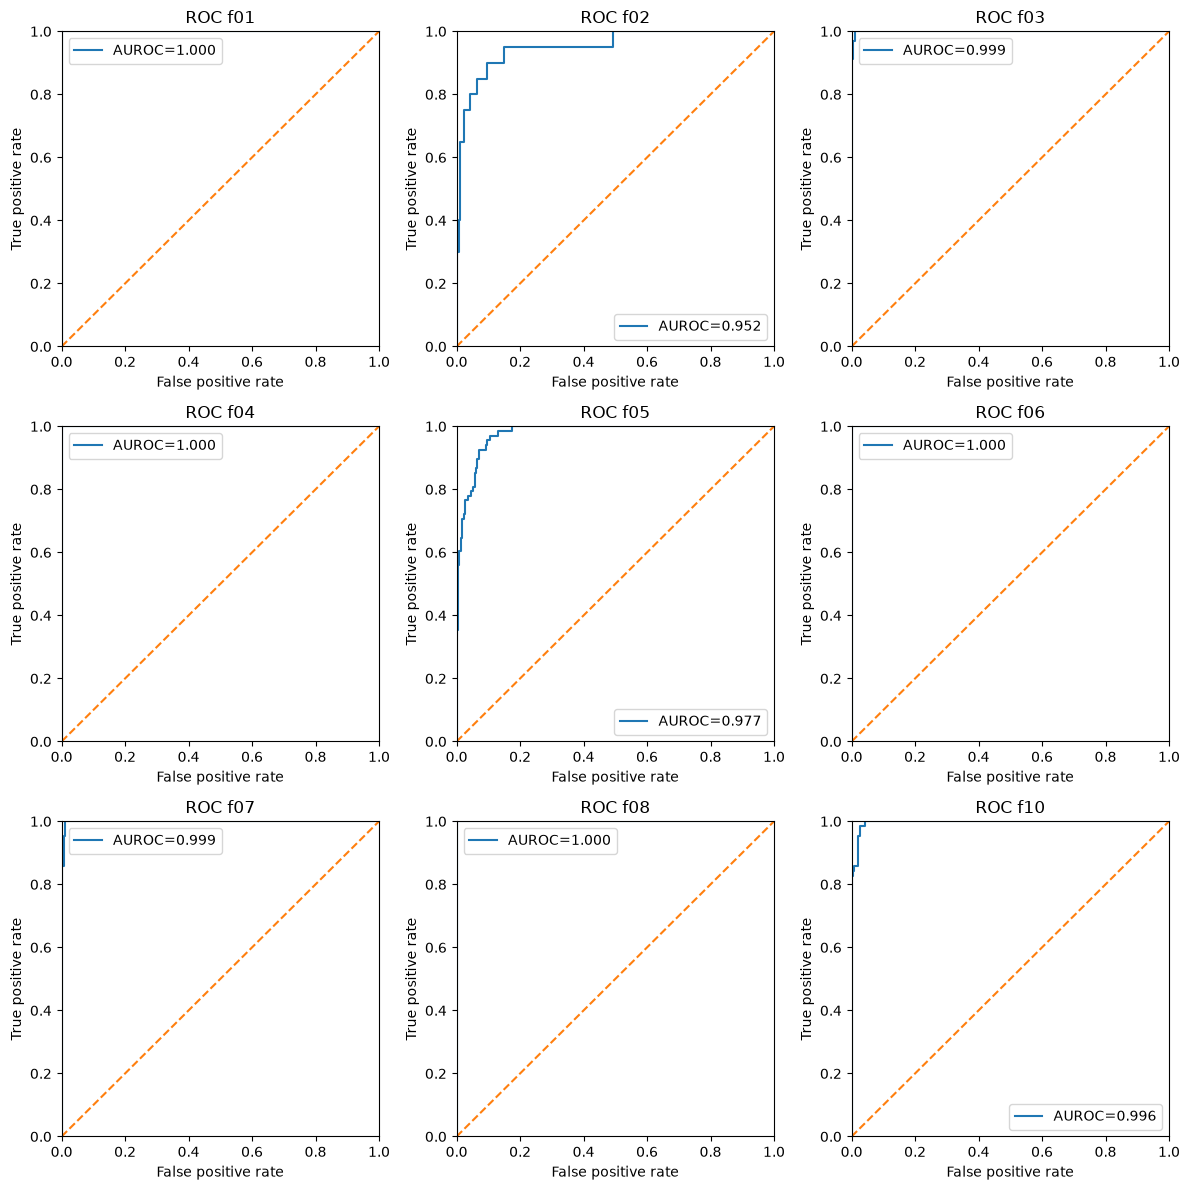

In [12]:
ncols = 3
nrows = int(np.ceil(len(USABLE_CODES) / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(12, 4 * nrows),
    squeeze=False,
)

for ax, code in zip(axes.ravel(), USABLE_CODES):
    d = ROC_DATA[code]

    ax.plot(
        d["fpr"],
        d["tpr"],
        label=f"AUROC={d['auroc']:.3f}",
    )
    ax.plot([0, 1], [0, 1], linestyle="--")
    ax.set(
        title=f"ROC {code}",
        xlabel="False positive rate",
        ylabel="True positive rate",
        xlim=(0, 1),
        ylim=(0, 1),
    )
    ax.legend()

for ax in axes.ravel()[len(USABLE_CODES):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 10. Choose thresholds at FPR ≤ 5%

`[PAPER]` The authors begin from operating points corresponding approximately to 5% FPR, seeking high
TPR while controlling false alarms.

For this replication:

1. retain finite ROC points with `FPR <= 0.05`;
2. select the point with the highest TPR;
3. when several points have equal TPR, choose the larger threshold as a conservative tie-break.

The paper's subsequent manual field fine-tuning cannot be reproduced from the available ground truth.

In [13]:
def threshold_at_fpr(roc_entry, max_fpr=TARGET_MAX_FPR):
    fpr = roc_entry["fpr"]
    tpr = roc_entry["tpr"]
    thresholds = roc_entry["thresholds"]

    feasible = np.where(
        (fpr <= max_fpr)
        & np.isfinite(thresholds)
    )[0]

    if len(feasible) == 0:
        raise RuntimeError(
            f"No finite threshold satisfies FPR <= {max_fpr} "
            f"for {roc_entry['code']}."
        )

    best_tpr = np.max(tpr[feasible])
    tied = feasible[np.isclose(tpr[feasible], best_tpr)]
    idx = tied[np.argmax(thresholds[tied])]

    return (
        float(thresholds[idx]),
        float(fpr[idx]),
        float(tpr[idx]),
    )


threshold_rows = []

for code in USABLE_CODES:
    threshold, fpr, tpr = threshold_at_fpr(
        ROC_DATA[code]
    )

    species_name = usable_inventory.loc[
        usable_inventory["code"] == code,
        "species",
    ].iloc[0]

    threshold_rows.append({
        "code": code,
        "species": species_name,
        "threshold": threshold,
        "fpr": fpr,
        "tpr": tpr,
        "auroc": ROC_DATA[code]["auroc"],
        "n_positive": ROC_DATA[code]["n_positive"],
        "n_negative": ROC_DATA[code]["n_negative"],
    })

thresholds = pd.DataFrame(threshold_rows)
THRESHOLD_BY_CODE = thresholds.set_index("code")["threshold"].to_dict()

display(thresholds.round(4))

,code,species,threshold,fpr,tpr,auroc,n_positive,n_negative
0,f01,Boana alfaroi,22.1950,0.0000,1.0000,1.0000,20,276
1,f02,Dendropsophus bifurcus,23.8904,0.0435,0.8000,0.9522,20,276
2,f03,Boana cinerascens,26.4991,0.0115,1.0000,0.9994,34,262
3,f04,Pristimantis conspicillatus,22.1101,0.0000,1.0000,1.0000,38,258
4,f05,Leptodactylus discodactylus,31.3620,0.0439,0.7941,0.9774,68,228
5,f06,Osteocephalus fuscifacies,16.6902,0.0000,1.0000,1.0000,11,285
6,f07,Boana lanciformis,24.6576,0.0109,1.0000,0.9988,21,275
7,f08,Rhinella margaritifera,37.8728,0.0000,1.0000,1.0000,20,276
8,f10,Engystomops petersi,26.1655,0.0431,1.0000,0.9963,64,232


### Paper thresholds, reference only

The paper reports the final vector

`[5, 3, 6, 9, 6.75, 5.25, 5.5, 11, 6, 6]`

for `f01 ... f10`.

Those values were fine-tuned with field material and must not be silently substituted for thresholds
calibrated on this different recovered dataset.

In [14]:
PAPER_FINAL_THRESHOLDS = {
    "f01": 5.0,
    "f02": 3.0,
    "f03": 6.0,
    "f04": 9.0,
    "f05": 6.75,
    "f06": 5.25,
    "f07": 5.5,
    "f08": 11.0,
    "f09": 6.0,
    "f10": 6.0,
}

comparison = thresholds.copy()
comparison["paper_final_reference"] = comparison["code"].map(
    PAPER_FINAL_THRESHOLDS
)
comparison["difference_from_paper"] = (
    comparison["threshold"]
    - comparison["paper_final_reference"]
)

display(
    comparison[
        [
            "code",
            "threshold",
            "paper_final_reference",
            "difference_from_paper",
            "fpr",
            "tpr",
            "auroc",
        ]
    ].round(4)
)

,code,threshold,paper_final_reference,difference_from_paper,fpr,tpr,auroc
0,f01,22.1950,5.00,17.1950,0.0000,1.0000,1.0000
1,f02,23.8904,3.00,20.8904,0.0435,0.8000,0.9522
2,f03,26.4991,6.00,20.4991,0.0115,1.0000,0.9994
3,f04,22.1101,9.00,13.1101,0.0000,1.0000,1.0000
4,f05,31.3620,6.75,24.6120,0.0439,0.7941,0.9774
5,f06,16.6902,5.25,11.4402,0.0000,1.0000,1.0000
6,f07,24.6576,5.50,19.1576,0.0109,1.0000,0.9988
7,f08,37.8728,11.00,26.8728,0.0000,1.0000,1.0000
8,f10,26.1655,6.00,20.1655,0.0431,1.0000,0.9963


## 11. Verify the selected operating points

These metrics are measured on the same CALIBRATION set used to select the thresholds, so they are
**calibration diagnostics**, not independent generalization estimates.

In [15]:
op_rows = []

for code in USABLE_CODES:
    subset = calibration_scores[
        calibration_scores["candidate_code"] == code
    ]

    y_true = subset["is_positive"].to_numpy(dtype=int)
    y_pred = (
        subset["llr"].to_numpy()
        >= THRESHOLD_BY_CODE[code]
    ).astype(int)

    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))

    op_rows.append({
        "code": code,
        "threshold": THRESHOLD_BY_CODE[code],
        "TP": tp,
        "FN": fn,
        "FP": fp,
        "TN": tn,
        "TPR": tp / (tp + fn),
        "FPR": fp / (fp + tn),
        "precision": tp / (tp + fp) if (tp + fp) else np.nan,
    })

operating_points = pd.DataFrame(op_rows)
display(operating_points.round(4))

assert (operating_points["FPR"] <= TARGET_MAX_FPR + 1e-12).all()
print("Every selected operating point respects FPR <= 5%.")

,code,threshold,TP,FN,FP,TN,TPR,FPR,precision
0,f01,22.1950,20,0,0,276,1.0000,0.0000,1.0000
1,f02,23.8904,16,4,12,264,0.8000,0.0435,0.5714
2,f03,26.4991,34,0,3,259,1.0000,0.0115,0.9189
3,f04,22.1101,38,0,0,258,1.0000,0.0000,1.0000
4,f05,31.3620,54,14,10,218,0.7941,0.0439,0.8438
5,f06,16.6902,11,0,0,285,1.0000,0.0000,1.0000
6,f07,24.6576,21,0,3,272,1.0000,0.0109,0.8750
7,f08,37.8728,20,0,0,276,1.0000,0.0000,1.0000
8,f10,26.1655,64,0,10,222,1.0000,0.0431,0.8649


Every selected operating point respects FPR <= 5%.


## 12. Frozen detector interface

For a candidate segment:

1. calculate the normalized log-likelihood under every frozen GMM;
2. select the model with the largest score as the species hypothesis;
3. subtract the median of the other model scores;
4. compare that LLR with the threshold calibrated for the hypothesized species.

There is no training inside this function.

In [16]:
def verify_segment(
    X_segment,
    models=FROZEN_MODELS,
    thresholds_by_code=THRESHOLD_BY_CODE,
):
    scores = model_scores(X_segment, models)

    hypothesis = max(scores, key=scores.get)

    alternative_median = float(
        np.median([
            score
            for code, score in scores.items()
            if code != hypothesis
        ])
    )

    llr = float(
        scores[hypothesis] - alternative_median
    )

    threshold = float(
        thresholds_by_code[hypothesis]
    )

    return {
        "hypothesis": hypothesis,
        "hypothesis_score": float(scores[hypothesis]),
        "alternative_median": alternative_median,
        "llr": llr,
        "threshold": threshold,
        "accepted": bool(llr >= threshold),
    }


smoke_true = USABLE_CODES[0]
smoke_call = CALIBRATION_IDS[smoke_true][0]
smoke_result = verify_segment(
    get_call_features(smoke_call)
)

print("Call       :", smoke_call)
print("True class :", smoke_true)
print("Detector   :", smoke_result)

Call       : call_0018
True class : f01
Detector   : {'hypothesis': 'f01', 'hypothesis_score': -32.1623141692261, 'alternative_median': -73.33620886855306, 'llr': 41.17389469932696, 'threshold': 22.19503597045658, 'accepted': True}


## 13. End-to-end calibration behavior

This combines identification and verification on every held-out calibration call.

A call counts as a correct accepted detection only when:

- the highest-scoring GMM is the true species;
- the corresponding LLR also passes that species threshold.

Again, these values describe the calibration set, not an external test set.

In [17]:
detector_rows = []

for true_code in USABLE_CODES:
    for call_id in CALIBRATION_IDS[true_code]:
        result = verify_segment(
            get_call_features(call_id)
        )

        detector_rows.append({
            "call_id": call_id,
            "true_code": true_code,
            "hypothesis": result["hypothesis"],
            "correct_hypothesis": result["hypothesis"] == true_code,
            "accepted": result["accepted"],
            "llr": result["llr"],
            "threshold": result["threshold"],
            "correct_and_accepted": (
                result["hypothesis"] == true_code
                and result["accepted"]
            ),
        })

detector_calibration = pd.DataFrame(detector_rows)

detector_summary = (
    detector_calibration
    .groupby("true_code", as_index=False)
    .agg(
        n_calls=("call_id", "size"),
        identification_accuracy=("correct_hypothesis", "mean"),
        acceptance_rate=("accepted", "mean"),
        correct_acceptance_rate=("correct_and_accepted", "mean"),
    )
)

display(detector_summary.round(4))

print(
    "Macro identification accuracy:",
    round(detector_summary["identification_accuracy"].mean() * 100, 3),
    "%"
)
print(
    "Macro correct+accepted rate:",
    round(detector_summary["correct_acceptance_rate"].mean() * 100, 3),
    "%"
)

,true_code,n_calls,identification_accuracy,acceptance_rate,correct_acceptance_rate
0,f01,20,1.00,1.0000,1.0000
1,f02,20,0.95,0.8000,0.8000
2,f03,34,1.00,1.0000,1.0000
3,f04,38,1.00,1.0000,1.0000
4,f05,68,1.00,0.7941,0.7941
5,f06,11,1.00,1.0000,1.0000
6,f07,21,1.00,1.0000,1.0000
7,f08,20,1.00,1.0000,1.0000
8,f10,64,1.00,1.0000,1.0000


Macro identification accuracy: 99.444 %
Macro correct+accepted rate: 95.49 %


## 14. Save the paired detector artifacts

Notebook 05 must consume the models and thresholds generated together here.

The files are written to new directories so they cannot be confused with the previous incompatible
notebook-04 artifacts.

In [18]:
for code, model in FROZEN_MODELS.items():
    joblib.dump(
        model,
        MODEL_DIR / f"{code}_gmm.joblib",
    )

manifest_rows = []

for code in USABLE_CODES:
    for call_id in TRAIN_IDS[code]:
        manifest_rows.append({
            "call_id": call_id,
            "code": code,
            "split": "train",
        })

    for call_id in CALIBRATION_IDS[code]:
        manifest_rows.append({
            "call_id": call_id,
            "code": code,
            "split": "calibration",
        })

split_manifest = pd.DataFrame(manifest_rows)

split_summary.to_csv(CALIBRATION_DIR / "split_summary.csv", index=False)
split_manifest.to_csv(CALIBRATION_DIR / "split_manifest.csv", index=False)
model_summary.to_csv(CALIBRATION_DIR / "frozen_models.csv", index=False)
calibration_scores.to_csv(CALIBRATION_DIR / "calibration_llr_scores.csv", index=False)
roc_overview.to_csv(CALIBRATION_DIR / "roc_overview.csv", index=False)
thresholds.to_csv(CALIBRATION_DIR / "thresholds.csv", index=False)
operating_points.to_csv(CALIBRATION_DIR / "operating_points.csv", index=False)
detector_calibration.to_csv(
    CALIBRATION_DIR / "detector_calibration_calls.csv",
    index=False,
)
detector_summary.to_csv(
    CALIBRATION_DIR / "detector_calibration_summary.csv",
    index=False,
)

metadata = {
    "model_order": MODEL_ORDER,
    "calibration_fraction": CALIBRATION_FRACTION,
    "target_max_fpr": TARGET_MAX_FPR,
    "base_seed": BASE_SEED,
    "classes": list(USABLE_CODES),
    "excluded_codes": sorted(EXCLUDED_CODES),
    "split_unit": "complete_call",
    "split_policy": (
        "fixed per-species split; ceil(20%) calibration and remaining calls training"
    ),
    "threshold_rule": (
        "highest TPR among finite ROC points with FPR <= 0.05; "
        "largest threshold on TPR ties"
    ),
    "freeze_rule": (
        "GMMs are fit once on TRAIN only and never re-fit after calibration"
    ),
    "paper_difference": (
        "the paper reports all labelled development material for production GMMs "
        "and field-based threshold fine-tuning; the complete field calibration "
        "ground truth is unavailable in this replication"
    ),
}

with open(
    CALIBRATION_DIR / "detector_metadata.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(metadata, f, indent=2)

print("Calibration artifacts:")
for p in sorted(CALIBRATION_DIR.iterdir()):
    print(" ", p.name)

print("\nFrozen GMMs:")
for p in sorted(MODEL_DIR.glob("*_gmm.joblib")):
    print(" ", p.name)

Calibration artifacts:
  calibration_llr_scores.csv
  detector_calibration_calls.csv
  detector_calibration_summary.csv
  detector_metadata.json
  frozen_models.csv
  operating_points.csv
  roc_overview.csv
  split_manifest.csv
  split_summary.csv
  thresholds.csv

Frozen GMMs:
  f01_gmm.joblib
  f02_gmm.joblib
  f03_gmm.joblib
  f04_gmm.joblib
  f05_gmm.joblib
  f06_gmm.joblib
  f07_gmm.joblib
  f08_gmm.joblib
  f10_gmm.joblib


## 15. Final consistency checks

Notebook 05 should start only after every check below passes.

In [19]:
assert set(FROZEN_MODELS) == set(USABLE_CODES)
assert set(THRESHOLD_BY_CODE) == set(USABLE_CODES)
assert all_train.isdisjoint(all_calibration)
assert (operating_points["FPR"] <= TARGET_MAX_FPR + 1e-12).all()

for code, model in FROZEN_MODELS.items():
    assert model.n_components == MODEL_ORDER
    assert model.covariance_type == "diag"

expected_files = {
    f"{code}_gmm.joblib"
    for code in USABLE_CODES
}
actual_files = {
    p.name
    for p in MODEL_DIR.glob("*_gmm.joblib")
}

missing_files = expected_files - actual_files
if missing_files:
    raise AssertionError(
        f"Missing serialized models: {sorted(missing_files)}"
    )

print("Detector consistency checks: OK")
print("Frozen model/threshold pair is ready for notebook 05.")

Detector consistency checks: OK
Frozen model/threshold pair is ready for notebook 05.


## 16. Conclusions and limitations

### This version guarantees

1. no complete call appears in both TRAIN and CALIBRATION;
2. final GMMs are trained only on TRAIN;
3. calibration data never enter GMM fitting;
4. thresholds are derived from scores produced by those exact frozen GMMs;
5. GMMs are never re-trained after threshold selection;
6. per-class thresholds satisfy the recoverable `FPR <= 5%` ROC criterion;
7. models, thresholds, split membership and provenance are saved together.

### Limitations

- `f09` is not available in sufficient labelled quantity.
- The 80/20 split is a replication decision, not a parameter reported in the paper.
- The paper fine-tuned final thresholds with manually annotated field material that cannot be fully
  reconstructed here.
- Because of that missing field calibration set, this implementation cannot simultaneously reproduce
  the paper's "train production GMMs on all labelled development material" step and retain a clean
  independent threshold-calibration set.
- Metrics measured on CALIBRATION are operating-point diagnostics, not external test performance.

### Next step

Notebook 05 should use the frozen artifacts from this notebook:

**pond WAV → 30 s blocks → species-band FIR segmentation → 10 ms STE → moving average →
endpoint detection → original unfiltered segment → 20 m-FCC → frozen GMMs → LLR →
fixed threshold → detections → presence/absence per 10-minute sample.**